# Face Recognition – Liveness Detection

This notebook builds a face anti-spoofing model to distinguish real faces from fake presentations using the Zalo AI Challenge 2022 dataset.

The model is trained on video frames extracted from the training videos and evaluated using classification metrics to measure its ability to detect real and spoof faces.

In [1]:
import os
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

from tqdm.auto import tqdm

### 1. Configure Project Paths and Settings

This section defines the project directories, dataset locations, and training configuration.

The dataset is stored in the project root directory. Model checkpoints and evaluation results will be saved in the `runs/liveness` directory.

# Dataset source:
# https://www.kaggle.com/datasets/hlly34/liveness-detection-zalo-2022

In [2]:
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATASET_DIR = PROJECT_ROOT / "Zalo AI Challenge 2022 dataset"

TRAIN_VIDEO_DIR = DATASET_DIR / "train" / "train" / "videos"
TRAIN_LABEL_FILE = DATASET_DIR / "train" / "train" / "label.csv"

PUBLIC_TEST_DIR = DATASET_DIR / "public_test" / "public" / "videos"
PUBLIC_TEST_2_DIR = DATASET_DIR / "public_test_2" / "public_test_2" / "videos"
PRIVATE_TEST_DIR = DATASET_DIR / "private_test" / "private_test" / "videos"

OUTPUT_DIR = PROJECT_ROOT / "runs" / "liveness"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 1e-4
NUM_FRAMES = 5

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### 2. Load Training Labels

This section loads the training labels from the CSV file and constructs the corresponding video paths.

It also checks whether each video file exists before proceeding with frame extraction.

In [3]:
assert TRAIN_VIDEO_DIR.exists(), "Training video directory was not found."
assert TRAIN_LABEL_FILE.exists(), "Training label CSV was not found."

labels_df = pd.read_csv(TRAIN_LABEL_FILE)

labels_df["fname"] = labels_df["fname"].astype(str).str.strip()
labels_df["liveness_score"] = pd.to_numeric(
    labels_df["liveness_score"],
    errors="raise"
)

labels_df["video_path"] = labels_df["fname"].apply(
    lambda filename: TRAIN_VIDEO_DIR / filename
)

labels_df["file_exists"] = labels_df["video_path"].apply(
    lambda path: path.is_file()
)

labels_df.head(10)

,fname,liveness_score,video_path,file_exists
0,1.mp4,0,c:\Users\Helios\Documents\School Project\COS30...,True
1,2.mp4,1,c:\Users\Helios\Documents\School Project\COS30...,True
2,3.mp4,1,c:\Users\Helios\Documents\School Project\COS30...,True
3,5.mp4,0,c:\Users\Helios\Documents\School Project\COS30...,True
4,7.mp4,1,c:\Users\Helios\Documents\School Project\COS30...,True
5,8.mp4,1,c:\Users\Helios\Documents\School Project\COS30...,True
6,10.mp4,0,c:\Users\Helios\Documents\School Project\COS30...,True
7,11.mp4,1,c:\Users\Helios\Documents\School Project\COS30...,True
8,12.mp4,0,c:\Users\Helios\Documents\School Project\COS30...,True
9,13.mp4,1,c:\Users\Helios\Documents\School Project\COS30...,True


### 3. Analyze Label Distribution

This section examines the distribution of liveness labels in the training dataset.

The number and percentage of videos in each class are calculated to identify potential class imbalance.

In [4]:
label_distribution = (
    labels_df["liveness_score"]
    .value_counts()
    .sort_index()
    .rename_axis("liveness_score")
    .reset_index(name="video_count")
)

label_distribution["percentage"] = (
    label_distribution["video_count"]
    / label_distribution["video_count"].sum()
    * 100
)

label_distribution

,liveness_score,video_count,percentage
0,0,570,48.80137
1,1,598,51.19863


### 4. Inspect Video Properties

This section examines the properties of a sample training video, including its frame count, frame rate, and resolution.

Several frames are extracted and displayed to verify that the videos can be read correctly before processing the entire dataset.

,Property,Value
0,Filename,1.mp4
1,Frame Count,126
2,FPS,24.92
3,Width,480
4,Height,852
5,Duration (seconds),5.05618


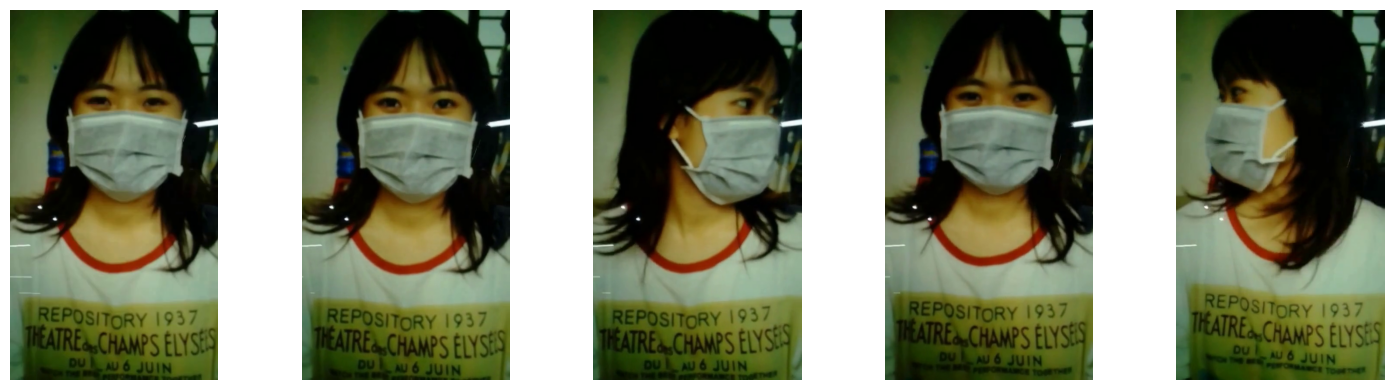

In [5]:
sample_video_path = labels_df.loc[0, "video_path"]

cap = cv2.VideoCapture(str(sample_video_path))

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {sample_video_path}")

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

video_info = pd.DataFrame({
    "Property": ["Filename", "Frame Count", "FPS", "Width", "Height", "Duration (seconds)"],
    "Value": [
        sample_video_path.name,
        frame_count,
        fps,
        width,
        height,
        frame_count / fps if fps > 0 else None
    ]
})

display(video_info)

frame_positions = np.linspace(
    0,
    max(frame_count - 1, 0),
    num=min(5, frame_count),
    dtype=int
)

sample_frames = []

for position in frame_positions:
    cap.set(cv2.CAP_PROP_POS_FRAMES, position)
    success, frame = cap.read()

    if success:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        sample_frames.append(frame)

cap.release()

fig, axes = plt.subplots(1, len(sample_frames), figsize=(15, 4))

if len(sample_frames) == 1:
    axes = [axes]

for ax, frame in zip(axes, sample_frames):
    ax.imshow(frame)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 5. Split Training and Validation Videos

This section splits the dataset into training and validation sets at the video level.

A stratified 80/20 split is used to maintain a similar distribution of fake and real videos in both sets.

All frames extracted from the same video will remain in the same split to prevent data leakage.

In [6]:
train_videos, val_videos = train_test_split(
    labels_df,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=labels_df["liveness_score"]
)

train_videos = train_videos.reset_index(drop=True)
val_videos = val_videos.reset_index(drop=True)

split_distribution = pd.DataFrame({
    "Training": train_videos["liveness_score"].value_counts().sort_index(),
    "Validation": val_videos["liveness_score"].value_counts().sort_index()
}).fillna(0).astype(int)

split_distribution.index = ["Fake (0)", "Real (1)"]

split_distribution.loc["Total"] = split_distribution.sum()

split_distribution

,Training,Validation
Fake (0),456,114
Real (1),478,120
Total,934,234


### 6. Extract Video Frames

This section extracts five evenly spaced frames from each video in the training and validation sets.

The extracted frames are resized to the target image size and saved separately for each split.

Each frame inherits the liveness label of its original video. The extracted dataset will be used to train the CNN model.

In [7]:
FRAME_DIR = OUTPUT_DIR / "frames"

TRAIN_FRAME_DIR = FRAME_DIR / "train"
VAL_FRAME_DIR = FRAME_DIR / "val"

for directory in [TRAIN_FRAME_DIR, VAL_FRAME_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


def extract_video_frames(video_path, output_dir, video_id, label):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return []

    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if frame_count <= 0:
        cap.release()
        return []

    frame_positions = np.linspace(
        0,
        frame_count - 1,
        num=min(NUM_FRAMES, frame_count),
        dtype=int
    )

    extracted_frames = []

    for frame_index, position in enumerate(frame_positions):
        cap.set(cv2.CAP_PROP_POS_FRAMES, position)
        success, frame = cap.read()

        if not success:
            continue

        frame = cv2.resize(
            frame,
            (IMAGE_SIZE, IMAGE_SIZE)
        )

        frame_filename = f"{video_id}_{frame_index}.jpg"
        frame_path = output_dir / frame_filename

        if cv2.imwrite(str(frame_path), frame):
            extracted_frames.append({
                "frame_path": frame_path,
                "label": int(label),
                "video_id": video_id
            })

    cap.release()

    return extracted_frames


train_frame_records = []
val_frame_records = []

for split_df, output_dir, records in [
    (train_videos, TRAIN_FRAME_DIR, train_frame_records),
    (val_videos, VAL_FRAME_DIR, val_frame_records)
]:
    for index, row in tqdm(
        split_df.iterrows(),
        total=len(split_df)
    ):
        video_id = Path(row["fname"]).stem

        extracted = extract_video_frames(
            video_path=row["video_path"],
            output_dir=output_dir,
            video_id=video_id,
            label=row["liveness_score"]
        )

        records.extend(extracted)


train_frames_df = pd.DataFrame(train_frame_records)
val_frames_df = pd.DataFrame(val_frame_records)

  0%|          | 0/934 [00:00<?, ?it/s]

  0%|          | 0/234 [00:00<?, ?it/s]

### 7. Verify Extracted Frames

This section checks the extracted frames from the training and validation videos.

It summarizes the number of extracted frames for each class and verifies that the frame extraction process completed successfully.

In [8]:
train_frame_summary = (
    train_frames_df.groupby("label")
    .size()
    .reindex([0, 1], fill_value=0)
    .rename("Training Frames")
)

val_frame_summary = (
    val_frames_df.groupby("label")
    .size()
    .reindex([0, 1], fill_value=0)
    .rename("Validation Frames")
)

frame_summary = pd.concat(
    [train_frame_summary, val_frame_summary],
    axis=1
)

frame_summary.index = ["Fake (0)", "Real (1)"]

frame_summary.loc["Total"] = frame_summary.sum()

display(frame_summary)

print("Total training frames:", len(train_frames_df))
print("Total validation frames:", len(val_frames_df))

assert not train_frames_df.empty, "No training frames were extracted."
assert not val_frames_df.empty, "No validation frames were extracted."

train_frames_df.to_csv(
    OUTPUT_DIR / "train_frames.csv",
    index=False
)

val_frames_df.to_csv(
    OUTPUT_DIR / "val_frames.csv",
    index=False
)

,Training Frames,Validation Frames
Fake (0),2280,570
Real (1),2390,600
Total,4670,1170


Total training frames: 4670
Total validation frames: 1170


### 8. Define the Liveness Dataset

This section creates a custom PyTorch Dataset for loading the extracted video frames.

Each image is converted to a tensor and normalized using ImageNet statistics to match the pretrained ResNet18 model.

In [9]:
from PIL import Image

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class LivenessDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["frame_path"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


train_dataset = LivenessDataset(
    train_frames_df,
    transform=train_transform
)

val_dataset = LivenessDataset(
    val_frames_df,
    transform=val_transform
)

### 9. Create DataLoaders

This section creates DataLoaders for the training and validation datasets.

The training DataLoader shuffles the samples, while the validation DataLoader preserves their original order.

In [10]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

### 10. Build the ResNet18 Model

This section initializes a pretrained ResNet18 model using ImageNet weights.

The final fully connected layer is replaced with a two-class classification layer to distinguish fake and real faces.

The model is moved to the available computing device.

In [11]:
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

### 11. Train the Liveness Model

This section trains the ResNet18 model using the extracted training frames.

The model is evaluated on the validation set after each epoch. The checkpoint with the lowest validation loss is saved for later evaluation.

Training loss and accuracy are recorded to monitor model performance.

In [12]:
best_val_loss = float("inf")
history = []

BEST_MODEL_PATH = OUTPUT_DIR / "best_liveness_model.pth"

for epoch in range(EPOCHS):
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS} - Training"
    )

    for images, labels in train_progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

        train_progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_train_loss = train_loss / train_total
    epoch_train_accuracy = train_correct / train_total

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_accuracy = val_correct / val_total

    scheduler.step(epoch_val_loss)

    history.append({
        "epoch": epoch + 1,
        "train_loss": epoch_train_loss,
        "train_accuracy": epoch_train_accuracy,
        "val_loss": epoch_val_loss,
        "val_accuracy": epoch_val_accuracy,
        "learning_rate": optimizer.param_groups[0]["lr"]
    })

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), BEST_MODEL_PATH)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_accuracy:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Accuracy: {epoch_val_accuracy:.4f}"
    )

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

Epoch 1/15 - Training:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch [1/15] Train Loss: 0.1376 | Train Accuracy: 0.9465 | Val Loss: 0.0826 | Val Accuracy: 0.9658


Epoch 2/15 - Training:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch [2/15] Train Loss: 0.0313 | Train Accuracy: 0.9914 | Val Loss: 0.1015 | Val Accuracy: 0.9641


Epoch 3/15 - Training:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch [3/15] Train Loss: 0.0196 | Train Accuracy: 0.9931 | Val Loss: 0.1876 | Val Accuracy: 0.9402


... (20 outputs left out)

Epoch 14/15 - Training:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch [14/15] Train Loss: 0.0038 | Train Accuracy: 0.9989 | Val Loss: 0.0938 | Val Accuracy: 0.9692


Epoch 15/15 - Training:   0%|          | 0/146 [00:00<?, ?it/s]

Epoch [15/15] Train Loss: 0.0009 | Train Accuracy: 1.0000 | Val Loss: 0.1126 | Val Accuracy: 0.9564


### 12. Visualize Training History

This section visualizes the training and validation loss and accuracy across epochs.

The plots help identify whether the model is learning effectively and whether overfitting occurs during training.

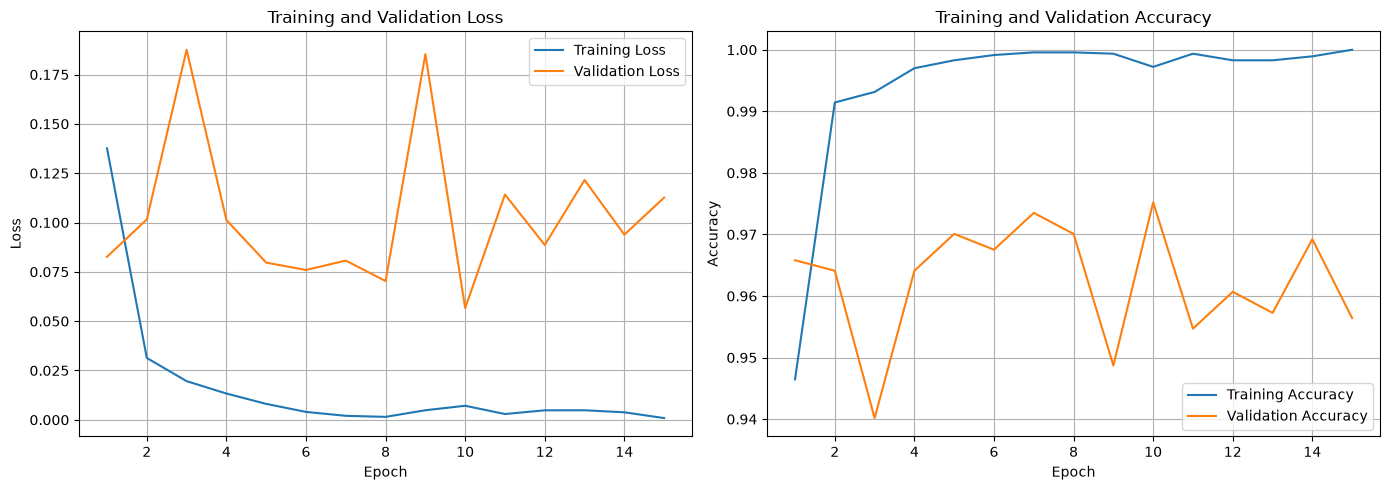

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_history.png", dpi=300)
plt.show()

### 13. Load the Best Model

This section reloads the checkpoint with the lowest validation loss.

The model is switched to evaluation mode before generating predictions.

In [15]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

model.eval();

### 14. Generate Validation Predictions

This section generates predictions for all validation frames using the best trained model.

The predicted probability of the real class is stored for each frame. These predictions will later be aggregated to produce video-level results.

In [16]:
frame_probabilities = []
frame_labels = []

model.eval()

with torch.no_grad():
    for images, labels in tqdm(
        val_loader,
        desc="Generating predictions"
    ):
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        frame_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

        frame_labels.extend(labels.numpy())

frame_results = val_frames_df.copy()

frame_results["true_label"] = frame_labels
frame_results["prob_real"] = frame_probabilities
frame_results["predicted_label"] = (
    frame_results["prob_real"] >= 0.5
).astype(int)

frame_results.to_csv(
    OUTPUT_DIR / "frame_predictions.csv",
    index=False
)

Generating predictions:   0%|          | 0/37 [00:00<?, ?it/s]

### 15. Aggregate Predictions at Video Level

This section combines frame-level predictions belonging to the same video.

The average probability of the real class is calculated for each video. A threshold of 0.5 is used to classify each video as fake or real.

This produces video-level predictions for the final evaluation.

In [17]:
video_results = (
    frame_results.groupby("video_id")
    .agg(
        true_label=("true_label", "first"),
        prob_real=("prob_real", "mean"),
        frame_count=("prob_real", "count")
    )
    .reset_index()
)

video_results["predicted_label"] = (
    video_results["prob_real"] >= 0.5
).astype(int)

video_results["true_label"] = video_results["true_label"].astype(int)

video_results.to_csv(
    OUTPUT_DIR / "video_predictions.csv",
    index=False
)

video_results.head()

,video_id,true_label,prob_real,frame_count,predicted_label
0,1007,1,0.981992,5,1
1,1014,0,0.001514,5,0
2,1018,1,1.000000,5,1
3,1026,0,0.000009,5,0
4,1029,0,0.467216,5,0


### 16. Evaluate Video-Level Performance

This section evaluates the model using video-level predictions.

Accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC are calculated to measure the model's ability to distinguish fake and real videos.

Real videos are treated as the positive class.

,Metric,Score
0,Accuracy,0.987179
1,Precision,1.000000
2,Recall,0.975000
3,F1-score,0.987342
4,ROC-AUC,0.999635


              precision    recall  f1-score   support

        Fake       0.97      1.00      0.99       114
        Real       1.00      0.97      0.99       120

    accuracy                           0.99       234
   macro avg       0.99      0.99      0.99       234
weighted avg       0.99      0.99      0.99       234



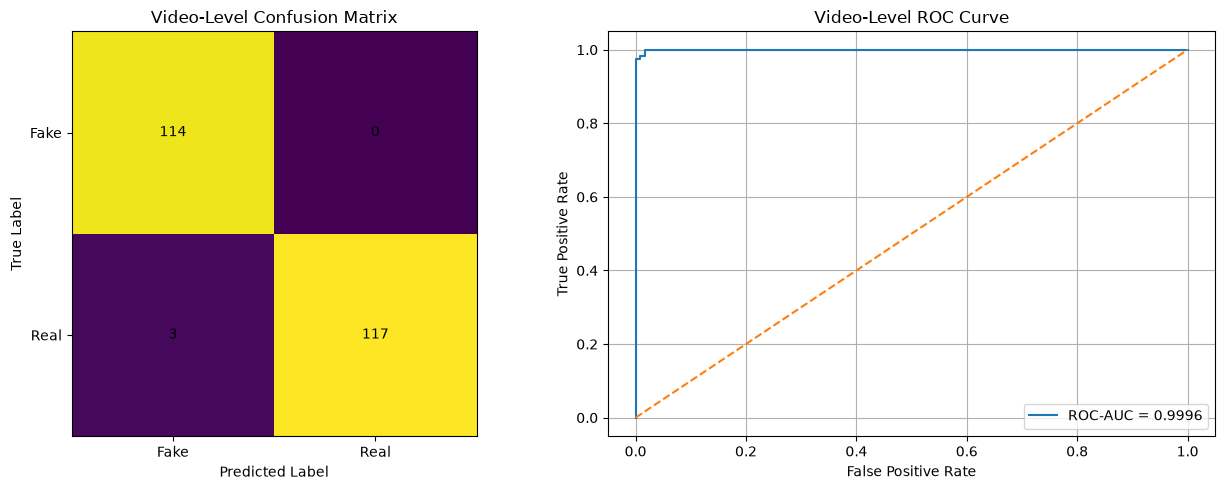

In [18]:
y_true = video_results["true_label"]
y_pred = video_results["predicted_label"]
y_score = video_results["prob_real"]

video_metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, pos_label=1),
    "Recall": recall_score(y_true, y_pred, pos_label=1),
    "F1-score": f1_score(y_true, y_pred, pos_label=1),
    "ROC-AUC": roc_auc_score(y_true, y_score)
}

metrics_df = pd.DataFrame(
    video_metrics.items(),
    columns=["Metric", "Score"]
)

display(metrics_df)

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Fake", "Real"],
        zero_division=0
    )
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(cm, interpolation="nearest")
axes[0].set_title("Video-Level Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")
axes[0].set_xticks([0, 1], ["Fake", "Real"])
axes[0].set_yticks([0, 1], ["Fake", "Real"])

for i in range(2):
    for j in range(2):
        axes[0].text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

fpr, tpr, thresholds = roc_curve(y_true, y_score)

axes[1].plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {video_metrics['ROC-AUC']:.4f}"
)

axes[1].plot([0, 1], [0, 1], linestyle="--")
axes[1].set_title("Video-Level ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "video_level_evaluation.png", dpi=300)
plt.show()

metrics_df.to_csv(
    OUTPUT_DIR / "video_level_metrics.csv",
    index=False
)

### 17. Save Final Model Information

This section saves the model configuration and final evaluation results.

The saved artifacts can be reused for future testing and integration into the facial recognition project.

In [19]:
model_info = {
    "model": "ResNet18",
    "pretrained": "ImageNet",
    "image_size": IMAGE_SIZE,
    "num_frames_per_video": NUM_FRAMES,
    "class_mapping": {
        "0": "Fake",
        "1": "Real"
    },
    "decision_threshold": 0.5,
    "best_validation_loss": best_val_loss,
    "epochs_trained": len(history_df),
    "video_level_metrics": video_metrics
}

pd.Series(model_info).to_json(
    OUTPUT_DIR / "model_info.json",
    indent=4
)

print("Best model:", BEST_MODEL_PATH)
print("Output directory:", OUTPUT_DIR)

Best model: c:\Users\Helios\Documents\School Project\COS30082 - Applied Machine Learning\Project - Facial Recognition with Emotion and Liveness\Project Code\runs\liveness\best_liveness_model.pth
Output directory: c:\Users\Helios\Documents\School Project\COS30082 - Applied Machine Learning\Project - Facial Recognition with Emotion and Liveness\Project Code\runs\liveness
